In [1]:
# Task 1: Import libraries
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
# Task 2: Settings (all fixed before running the experiment)
DATA_FILE = "post natal data.csv"
RESULTS_FOLDER = Path("results_cgth")
RESULTS_FOLDER.mkdir(exist_ok=True)

TARGET = "Feeling anxious"
SEED = 42
DELTA = 0.2                                      # confidence gate of the proposed hybrid
DELTA_GRID = np.round(np.arange(0, 0.55, 0.05), 2)
NON_INFERIORITY_MARGIN = 0.03                    # largest acceptable loss of balanced accuracy vs RF

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | pandas 3.0.5 | scikit-learn 1.9.0


In [3]:
# Task 3: Load the dataset (the CSV file is only read, never changed)
raw = pd.read_csv(DATA_FILE)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (1503, 11)


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


In [4]:
# Task 4: Data audit - how many rows are exact duplicates?
answers = raw.drop(columns="Timestamp")
unique_rows = answers.drop_duplicates().reset_index(drop=True)

print("Total rows:", len(answers))
print("Duplicate rows:", answers.duplicated().sum())
print("Unique rows:", len(unique_rows))

Total rows: 1503
Duplicate rows: 1177
Unique rows: 326


In [5]:
# Task 5: Clean data - unique rows only, features (X) and target (y)
def split_features_target(data):
    X = data.drop(columns=TARGET).astype(object)
    y = (data[TARGET] == "Yes").astype(int).to_numpy()
    return X, y


X, y = split_features_target(unique_rows)
print("Positive rate (Feeling anxious = Yes):", round(y.mean(), 3))

Positive rate (Feeling anxious = Yes): 0.58


In [6]:
# Task 6: Base models - missing values and encoding are learned inside each training fold
def preprocessing():
    return make_pipeline(SimpleImputer(strategy="most_frequent"),
                         OneHotEncoder(handle_unknown="ignore"))


def logistic_regression():
    return make_pipeline(preprocessing(), LogisticRegression(max_iter=1000))


def random_forest():
    return make_pipeline(preprocessing(),
                         RandomForestClassifier(n_estimators=300, max_depth=4, random_state=SEED))

In [7]:
# Task 7: Proposed method - Confidence-Gated Transparent Hybrid (CGTH)
# Step 1: the transparent model (Logistic Regression) decides every case it is confident about.
# Step 2: only uncertain cases (probability close to 0.5) are passed to the Random Forest.
def confidence_gated_hybrid(lr_prob, rf_prob, delta):
    decided_by_lr = np.abs(lr_prob - 0.5) >= delta
    final_prob = np.where(decided_by_lr, lr_prob, rf_prob)
    return final_prob, decided_by_lr


# Comparison hybrid: the usual soft-voting average of the same two models
def soft_voting(lr_prob, rf_prob):
    return (lr_prob + rf_prob) / 2

In [8]:
# Task 8: Evaluation metrics (decision threshold 0.5)
def decision_metrics(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "accuracy": accuracy_score(y_true, pred),
        "sensitivity": recall_score(y_true, pred),
        "specificity": recall_score(y_true, pred, pos_label=0),
        "f1": f1_score(y_true, pred),
        "mcc": matthews_corrcoef(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob),
    }

In [9]:
# Task 9: Experiment - 5-fold cross-validation repeated 10 times (50 folds)
def run_cv(X, y):
    scores, curve, gate_check = [], [], []
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

    for fold, (train, test) in enumerate(cv.split(X, y)):
        X_train, X_test = X.iloc[train], X.iloc[test]
        y_train, y_test = y[train], y[test]

        lr_prob = logistic_regression().fit(X_train, y_train).predict_proba(X_test)[:, 1]
        rf_prob = random_forest().fit(X_train, y_train).predict_proba(X_test)[:, 1]
        hybrid_prob, decided_by_lr = confidence_gated_hybrid(lr_prob, rf_prob, DELTA)

        predictions = {
            "Logistic Regression": lr_prob,
            "Random Forest": rf_prob,
            "Soft Voting (LR+RF)": soft_voting(lr_prob, rf_prob),
            "CGTH (proposed)": hybrid_prob,
        }
        for name, prob in predictions.items():
            row = {"fold": fold, "model": name, **decision_metrics(y_test, prob)}
            row["lr_coverage"] = decided_by_lr.mean() if name == "CGTH (proposed)" else np.nan
            scores.append(row)

        for delta in DELTA_GRID:
            prob, decided = confidence_gated_hybrid(lr_prob, rf_prob, delta)
            curve.append({"fold": fold, "delta": delta, "lr_coverage": decided.mean(),
                          "balanced_accuracy": balanced_accuracy_score(y_test, prob >= 0.5)})

        uncertain = ~decided_by_lr
        gate_check.append({
            "fold": fold,
            "LR on confident cases": accuracy_score(y_test[decided_by_lr], lr_prob[decided_by_lr] >= 0.5),
            "LR on uncertain cases": accuracy_score(y_test[uncertain], lr_prob[uncertain] >= 0.5),
            "RF on uncertain cases": accuracy_score(y_test[uncertain], rf_prob[uncertain] >= 0.5),
        })

    return pd.DataFrame(scores), pd.DataFrame(curve), pd.DataFrame(gate_check)


scores, curve, gate_check = run_cv(X, y)
scores.to_csv(RESULTS_FOLDER / "fold_scores.csv", index=False)

In [10]:
# Task 10: Results table - mean with corrected 95% confidence interval
# The Nadeau-Bengio correction widens the interval because CV training sets overlap.
N_TEST = len(y) / 5
N_TRAIN = len(y) - N_TEST


def corrected_se(values):
    return np.sqrt((1 / len(values) + N_TEST / N_TRAIN) * np.var(values, ddof=1))


def mean_with_ci(values):
    margin = stats.t.ppf(0.975, len(values) - 1) * corrected_se(values)
    return f"{values.mean():.3f} [{values.mean() - margin:.3f}, {values.mean() + margin:.3f}]"


metrics = ["balanced_accuracy", "accuracy", "sensitivity", "specificity", "f1", "mcc", "roc_auc"]
results = scores.groupby("model", sort=False)[metrics].agg(mean_with_ci)
results["lr_coverage"] = scores.groupby("model", sort=False)["lr_coverage"].mean().round(3)
results.to_csv(RESULTS_FOLDER / "results_table.csv")
results

,balanced_accuracy,accuracy,sensitivity,specificity,f1,mcc,roc_auc,lr_coverage
model,,,,,,,,
Logistic Regression,"0.730 [0.667, 0.794]","0.745 [0.682, 0.808]","0.821 [0.749, 0.893]","0.639 [0.553, 0.726]","0.788 [0.733, 0.843]","0.473 [0.343, 0.603]","0.800 [0.740, 0.859]",NaN
Random Forest,"0.761 [0.706, 0.816]","0.780 [0.728, 0.833]","0.881 [0.825, 0.937]","0.642 [0.553, 0.730]","0.823 [0.780, 0.866]","0.547 [0.436, 0.657]","0.835 [0.784, 0.886]",NaN
Soft Voting (LR+RF),"0.741 [0.678, 0.804]","0.760 [0.698, 0.822]","0.857 [0.784, 0.930]","0.626 [0.538, 0.713]","0.805 [0.752, 0.858]","0.504 [0.372, 0.636]","0.820 [0.765, 0.874]",NaN
CGTH (proposed),"0.757 [0.700, 0.813]","0.776 [0.722, 0.830]","0.878 [0.820, 0.936]","0.635 [0.547, 0.723]","0.820 [0.775, 0.864]","0.538 [0.423, 0.653]","0.809 [0.751, 0.867]",0.684


In [11]:
# Task 11: Hypothesis tests on balanced accuracy (paired by fold)
# H1: CGTH is non-inferior to Random Forest (loses less than the margin).
# H2: CGTH is better than Logistic Regression.
per_fold = scores.pivot(index="fold", columns="model", values="balanced_accuracy")
k = len(per_fold)

diff_rf = per_fold["CGTH (proposed)"] - per_fold["Random Forest"]
t_rf = (diff_rf.mean() + NON_INFERIORITY_MARGIN) / corrected_se(diff_rf)
p_rf = stats.t.sf(t_rf, df=k - 1)

diff_lr = per_fold["CGTH (proposed)"] - per_fold["Logistic Regression"]
t_lr = diff_lr.mean() / corrected_se(diff_lr)
p_lr = stats.t.sf(t_lr, df=k - 1)

tests = pd.DataFrame({
    "hypothesis": ["H1 CGTH non-inferior to RF", "H2 CGTH better than LR"],
    "mean_difference": [diff_rf.mean(), diff_lr.mean()],
    "t": [t_rf, t_lr],
    "one_sided_p": [p_rf, p_lr],
}).round(4)
tests["supported (p < 0.05)"] = tests["one_sided_p"] < 0.05
tests.to_csv(RESULTS_FOLDER / "hypothesis_tests.csv", index=False)
tests

,hypothesis,mean_difference,t,one_sided_p,supported (p < 0.05)
0,H1 CGTH non-inferior to RF,-0.0046,5.0147,0.0000,True
1,H2 CGTH better than LR,0.0264,1.4243,0.0803,False


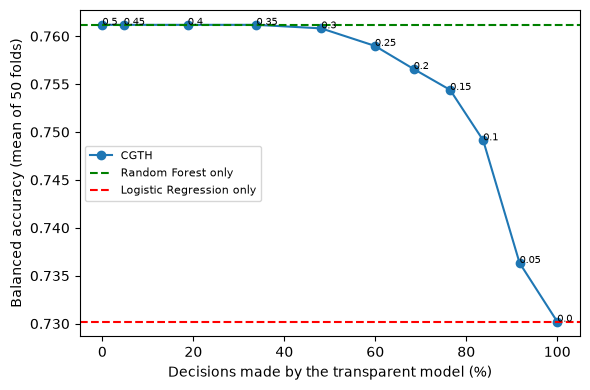

In [12]:
# Task 12: Figure - transparency vs performance for every gate value
mean_curve = curve.groupby("delta")[["lr_coverage", "balanced_accuracy"]].mean()
rf_score = per_fold["Random Forest"].mean()
lr_score = per_fold["Logistic Regression"].mean()

plt.figure(figsize=(6, 4))
plt.plot(mean_curve["lr_coverage"] * 100, mean_curve["balanced_accuracy"], marker="o", label="CGTH")
plt.axhline(rf_score, color="green", linestyle="--", label="Random Forest only")
plt.axhline(lr_score, color="red", linestyle="--", label="Logistic Regression only")
for delta, row in mean_curve.iterrows():
    plt.annotate(f"{delta}", (row["lr_coverage"] * 100, row["balanced_accuracy"]), fontsize=7)
plt.xlabel("Decisions made by the transparent model (%)")
plt.ylabel("Balanced accuracy (mean of 50 folds)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "transparency_vs_performance.png", dpi=300)
plt.show()

In [13]:
# Task 13: Why the gate works - accuracy on confident vs uncertain cases
gate_summary = gate_check.drop(columns="fold").mean().round(3).to_frame("mean_accuracy")
gate_summary.to_csv(RESULTS_FOLDER / "gate_check.csv")
gate_summary

,mean_accuracy
LR on confident cases,0.806
LR on uncertain cases,0.606
RF on uncertain cases,0.709


In [14]:
# Task 14: Explanation of the transparent part - Logistic Regression odds ratios
final_lr = logistic_regression().fit(X, y)
feature_names = final_lr[0][-1].get_feature_names_out(X.columns)
coefficients = final_lr[-1].coef_[0]

explanation = pd.DataFrame({"answer": feature_names, "odds_ratio": np.exp(coefficients)})
explanation["effect"] = np.where(coefficients > 0, "raises probability", "lowers probability")
explanation = explanation.reindex(np.argsort(-np.abs(coefficients))).head(10).round(3)
explanation.to_csv(RESULTS_FOLDER / "lr_odds_ratios.csv", index=False)
explanation

,answer,odds_ratio,effect
22,Feeling of guilt_Yes,0.226,lowers probability
21,Feeling of guilt_No,3.163,raises probability
15,Problems concentrating or making decision_Often,1.846,raises probability
9,Irritable towards baby & partner_Sometimes,0.572,lowers probability
27,Suicide attempt_Not interested to say,0.581,lowers probability
4,Age_45-50,1.671,raises probability
19,Overeating or loss of appetite_Yes,0.639,lowers probability
14,Problems concentrating or making decision_No,0.646,lowers probability
10,Irritable towards baby & partner_Yes,1.536,raises probability
17,Overeating or loss of appetite_No,1.449,raises probability


In [15]:
# Task 15: Robustness checks - duplicate leakage and dependence on the guilt item
X_dup, y_dup = split_features_target(answers)
dup_scores, _, _ = run_cv(X_dup, y_dup)
no_guilt_scores, _, _ = run_cv(X.drop(columns="Feeling of guilt"), y)

robustness = pd.DataFrame({
    "unique rows (main result)": scores.groupby("model")["balanced_accuracy"].mean(),
    "duplicates kept (leakage)": dup_scores.groupby("model")["balanced_accuracy"].mean(),
    "guilt item removed": no_guilt_scores.groupby("model")["balanced_accuracy"].mean(),
}).round(3)
robustness.to_csv(RESULTS_FOLDER / "robustness.csv")
robustness

,unique rows (main result),duplicates kept (leakage),guilt item removed
model,,,
CGTH (proposed),0.757,0.843,0.601
Logistic Regression,0.730,0.796,0.601
Random Forest,0.761,0.855,0.602
Soft Voting (LR+RF),0.741,0.813,0.601
